# SwiftRoute Logistics - Delivery Delay Prediction
## DSAI Mini Coursework

**Student name**: Thanh Diem Nguyen 

**Email**: thanhdiem0512@gmail.com 

**Discord username**: sophiedn  

**Submission date**: *(fill in)*

---

### Mark Scheme

| Section | Marks |
|---|---|
| 1 | 10 |
| 2 | 3 |
| 3 | 10 |
| 4 | 12 |
| 5 | 15 |
| 6 | 15 |
| 7 | 8 |
| 8 | 12 |
| 9 | 5 |
| Extension | 10 |
| **Total** | **100** |

---
# SECTION 1 - Understanding the Problem *(10 marks)*

**1.1** *(1 mark)* In one sentence, describe what SwiftRoute is trying to predict and why it matters.

*Your answer here.*

SwiftRoute wants to predict whether a shipment will be delayed at the time of pickup, so the company can take action early to reduce delays and avoid extra costs, leading to fewer unhappy customers.

---

**1.2** *(2 marks)* Is this a classification or regression problem? What is the target variable? What does one row in the training data represent?

*Your answer here.*

This is a binary classification problem because we predict whether a shipment is delayed or not.

The target variable is is_delayed, where 1 means delayed and 0 means on time.

Each row represents one shipment with information such as its route, carrier, service tier, and package details.

---

**1.3** *(3 marks)* Only ~12% of shipments are delayed. Explain why **accuracy** is a misleading metric here. What metric will you use instead, and what does it measure in the context of delivery operations?

*Your answer here.*

Accuracy can be misleading because only about 12% of shipments are delayed. If all shipments are predicted as on time, the accuracy would still be 88% without catching any delays.

I would use ROC-AUC instead to measure how well the model separates delayed shipments from on-time ones. A higher ROC-AUC means the model is better at ranking delayed shipments as higher risk, helping the Operations team identify which shipments need attention.


---

**1.4** *(2 marks)* The Operations team can only intervene on the top **15%** of highest-risk shipments. Describe the two types of mistake your model can make, and explain which is more costly to SwiftRoute.

*Your answer here.*

The model can make two types of mistakes: (1) False positive (FP): a shipment is flagged as high-risk but actually arrives on time, leading to unnecessary intervention costs. (2) False negative (FN): a shipment is not flagged when it is actually delayed, so the company misses the chance to intervene.

I think FN is more costly because the goal is to identify delays early and avoid SLA penalties. However, FP also matters because the Operations team can only intervene on 15% of shipments.

---

**1.5** *(2 marks)* The `weather_events` table stores disruptions as date ranges (start_date to end_date) by region. Explain the challenge of joining this to `shipments`, and what logic is needed.

*Your answer here.*

The challenge is that each weather event covers a range of dates for a region, while each shipment has only one pickup date. So, we cannot simply join these tables using an exact date match.

The solution is to check whether the shipment's pickup date falls within the event's date range and whether its origin or destination matches the event's region. This leads to several cases: (1) A shipment matches multiple events -> take the maximum severity. (2) No matching event -> severity = 0. By aggregating the matching events into one severity value per shipment before joining, we can avoid creating duplicate shipment rows.

---
# SECTION 2 - Setup & Data Loading *(3 marks)*

In [1]:
# *(1 mark)* Import libraries
import warnings; warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42

In [2]:
# *(2 marks)* Load all four CSV files. Print shape and first few rows of each.
# shipments = pd.read_csv('data/shipments.csv', parse_dates=['pickup_date'])
# routes    = pd.read_csv('data/routes.csv')
# carriers  = pd.read_csv('data/carriers.csv')
# weather   = pd.read_csv('data/weather_events.csv', parse_dates=['start_date','end_date'])

# Your code here
from swiftroute.dataset import load_dataset, check_dataset

data = load_dataset()

for name, df in data.items():
    print(f'{name}: {df.shape}')
    display(df.head(5))

shipments: (10025, 12)


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0


routes: (60, 7)


,route_id,origin_region,dest_region,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days
0,R0001,London,North_East,480,3,0.2471,2.92
1,R0002,Scotland,Yorkshire,139,1,0.1617,1.85
2,R0003,South_West,Midlands,191,1,0.1449,1.71
3,R0004,London,South_East,127,1,0.0450,1.85
4,R0005,Midlands,North_East,279,2,0.0970,1.96


carriers: (8, 7)


,carrier_id,carrier_name,tier_coverage,reliability_score,capacity_utilisation,avg_delay_mins,n_active_routes
0,C01,FastTrack,all,0.9508,0.5926,78.2,17
1,C02,PrimeMove,all,0.9049,0.6838,82.2,25
2,C03,SureDeliver,all,0.8605,0.6675,35.0,8
3,C04,QuickHaul,all,0.8332,0.7361,29.7,11
4,C05,NorthernPost,express_only,0.7640,0.8150,34.9,15


weather: (265, 6)


,event_id,region,event_type,severity,start_date,end_date
0,W00001,Midlands,high_wind,2,2024-01-03,2024-01-05
1,W00002,Yorkshire,snow,1,2024-01-26,2024-01-30
2,W00003,London,flood,1,2024-01-15,2024-01-18
3,W00004,North_East,high_wind,1,2024-01-26,2024-02-01
4,W00005,North_West,storm,2,2024-01-24,2024-01-26


---
# SECTION 3 - Exploring the Data (EDA) *(10 marks)*

### 3.1 Data Quality Check *(3 marks)*

In [3]:
# *(3 marks)* Check: dtypes, null counts, duplicates, referential integrity,
# and the overall delay rate.

# Your code here
check_dataset(data)


--- SHIPMENTS (10025, 12) ---
                         Dtype  Missing  Missing (%)
shipment_id                str        0         0.00
pickup_date     datetime64[us]        0         0.00
origin_region              str        0         0.00
dest_region                str        0         0.00
service_tier               str        0         0.00
carrier_id                 str        0         0.00
route_id                   str        0         0.00
weight_kg              float64      320         3.19
volume_cm3               int64        0         0.00
declared_value         float64      507         5.06
is_business              int64        0         0.00
is_delayed               int64        0         0.00
Duplicate rows: 0

--- ROUTES (60, 7) ---
                         Dtype  Missing  Missing (%)
route_id                   str        0          0.0
origin_region              str        0          0.0
dest_region                str        0          0.0
distance_km              i

**Commentary** - List quality issues and how you will handle each.

*Your answer here.*

The main issue is missing values in weight_kg (3.19%) and declared_value (5.06%). Since the missing percentages are relatively small, I will use median imputation instead of dropping rows to avoid losing useful shipment data. I will calculate the median from the training data only to prevent data leakage.

There are no duplicate rows or invalid carrier/route references, so no cleaning is needed for these issues. The other datasets also have no missing values.

The overall delay rate is only 11.91%, meaning most shipments arrive on time. Because of this imbalance, accuracy could be misleading (as explained in Section 1.3). Therefore, I will focus on ROC-AUC and the delay capture rate in the top 15% to evaluate how well the model identifies shipments at risk of delay.

### 3.2 Distribution of Key Columns *(2 marks)*

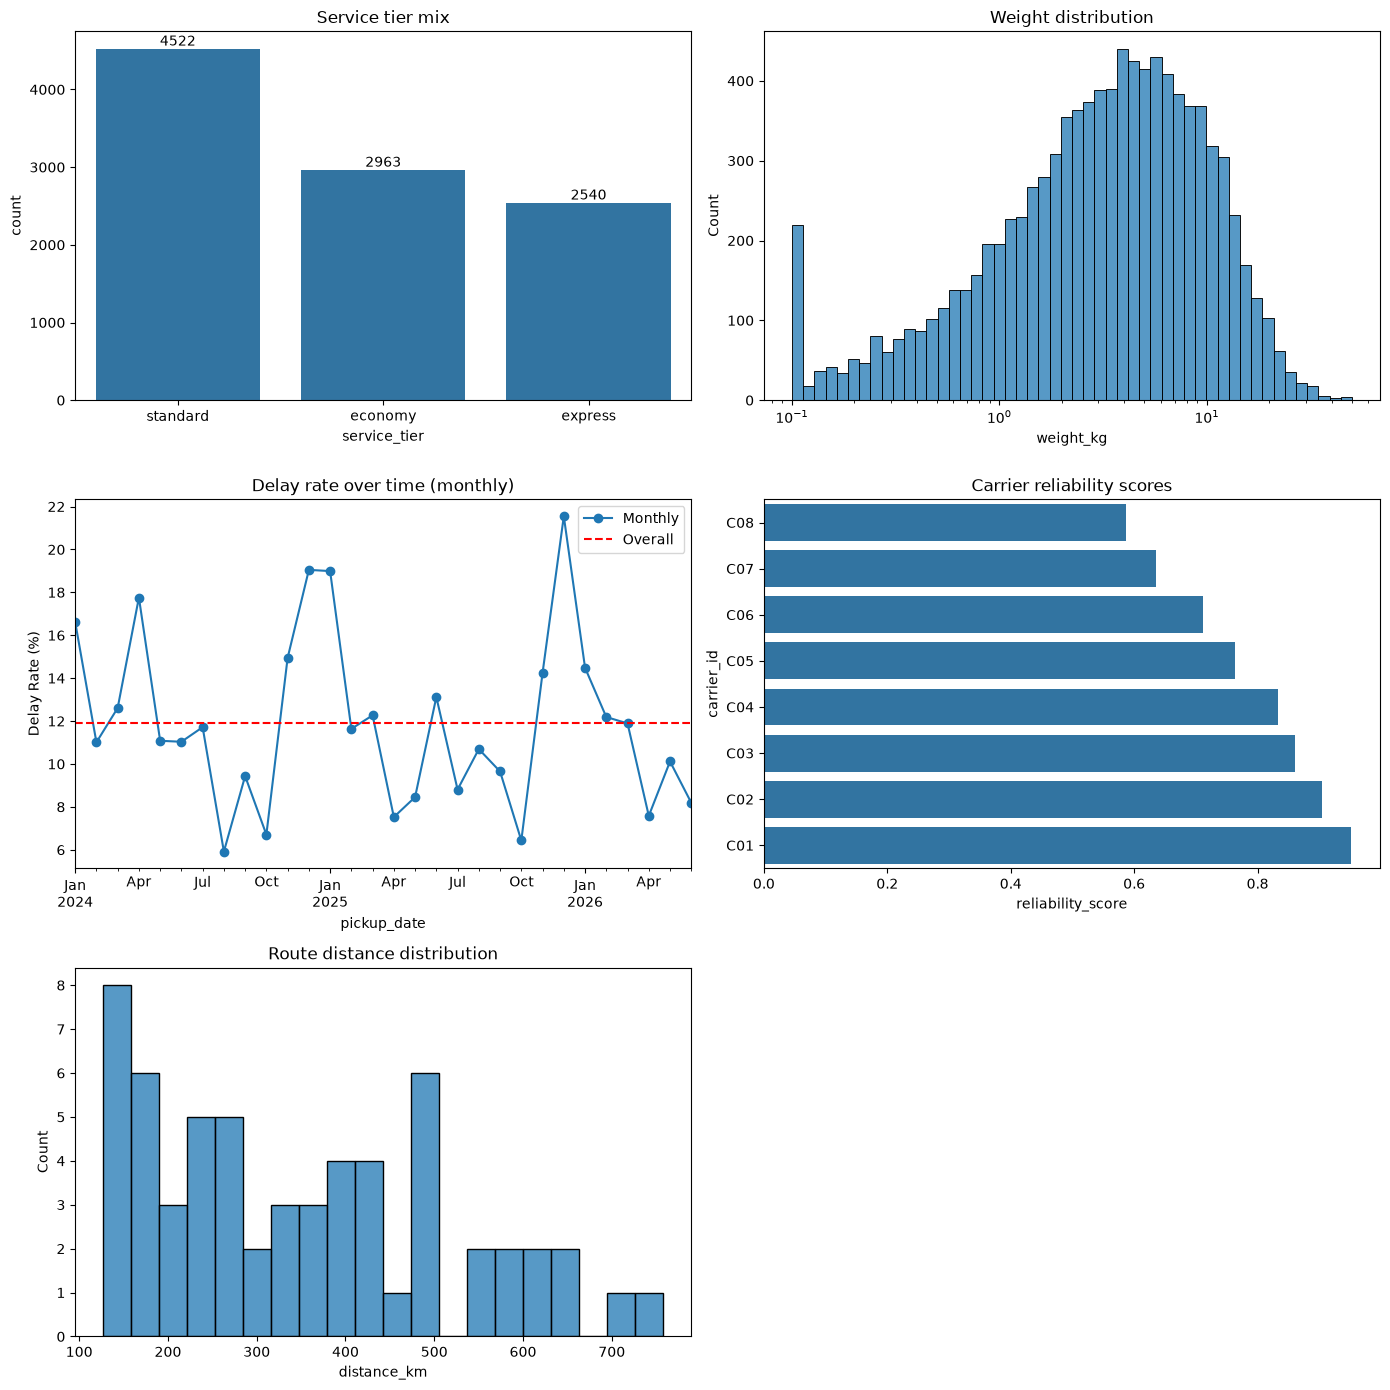

In [4]:
# *(2 marks)* Plot: service_tier mix, weight distribution, delay rate over time
# (monthly), carrier reliability scores, route distance distribution.

# Your code here
from swiftroute.plots import  plot_key_distributions

plot_key_distributions(data)


**Commentary** - Two interesting observations.

*Your answer here.*

1. Possible seasonal pattern in delays. The monthly delay rate peaks in winter (about 19% in Dec 2024 and Jan 2025, and above 21% in Dec 2025), well above the 11.9% average. Some summer and autumn months have lower rates of around 6-9%. This suggests that weather or seasonal demand may affect delays. I will consider adding an `is_winter` feature, and Operations may need extra capacity during high-risk months.

2. Weight is right-skewed, with an unusual spike at the minimum. On a log scale, most parcels weigh 1-10 kg, but 206 parcels have a weight of exactly 0.1 kg. This could be a minimum recorded value or a default value rather than their actual weights. I will inspect these records and consider a log transformation of weight_kg to reduce skewness.

### 3.3 Which Factors Are Related to Delays? *(3 marks)*

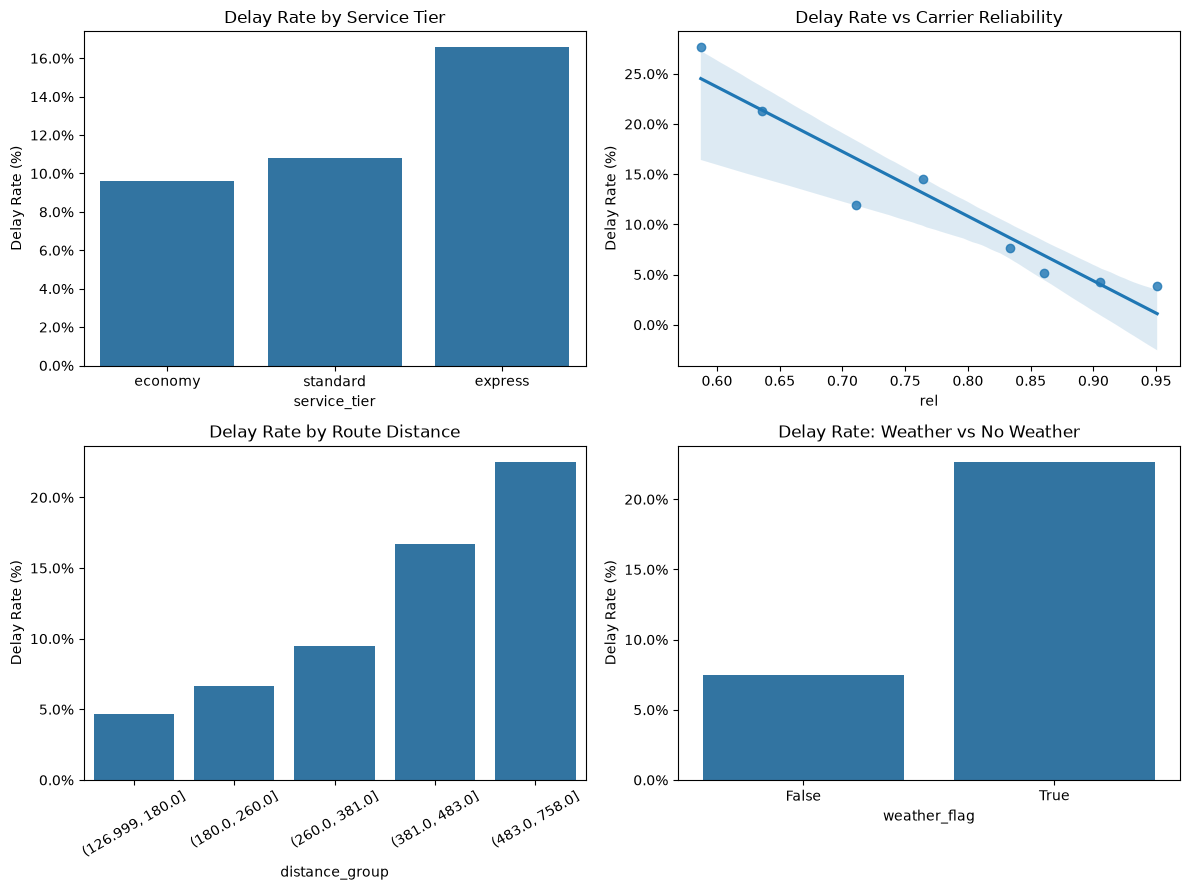

Delay rate (%)
Factor       Group                   
Service tier economy              9.6
             express             16.6
             standard            10.8
Weather flag False                7.5
             True                22.7

,Correlation with delay
reliability_score,-0.260
distance_km,0.214


In [5]:
# *(3 marks)* Explore delay rate vs:
# - service_tier
# - carrier (join to carriers.csv for reliability_score)
# - route distance (join to routes.csv)
# - weather (do shipments during weather events delay more?)

# Your code here
from swiftroute.plots import plot_delay_factors
eda = plot_delay_factors(data)

# Delay rate by tier and weather
tier = eda.groupby("service_tier")["is_delayed"].mean().mul(100).round(1)
weather = eda.groupby("weather_flag")["is_delayed"].mean().mul(100).round(1)
summary = pd.concat({"Service tier": tier, "Weather flag": weather}, names=["Factor", "Group"])
display(summary.rename("Delay rate (%)").to_frame())

# Correlation of reliability_score and distance_km with delay
display(eda[["reliability_score", "distance_km"]].corrwith(eda["is_delayed"]).round(3).rename("Correlation with delay").to_frame())


**Commentary** - Which factors show the strongest relationship with delays?

*Your answer here.*

From the plots, I noticed that carrier reliability and weather show the strongest relationships with delays.

For carrier reliability, I found a negative correlation (-0.260), meaning more reliable carriers tend to have fewer delays. The least reliable carrier has a delay rate of about 28%, compared to only 4% for the most reliable.

For weather, I observed that shipments affected by weather have a delay rate of 22.7%, compared to 7.5% without weather events, about three times higher.

I also found that route distance has a positive correlation (+0.214), with longer routes having higher delay rates. Service tier shows some differences, with Express having the highest delay rate (16.6%).

Based on these results, I think carrier reliability, weather, and route distance could be important features for predicting delays.

### 3.4 Which Routes and Carriers Are Riskiest? *(2 marks)*

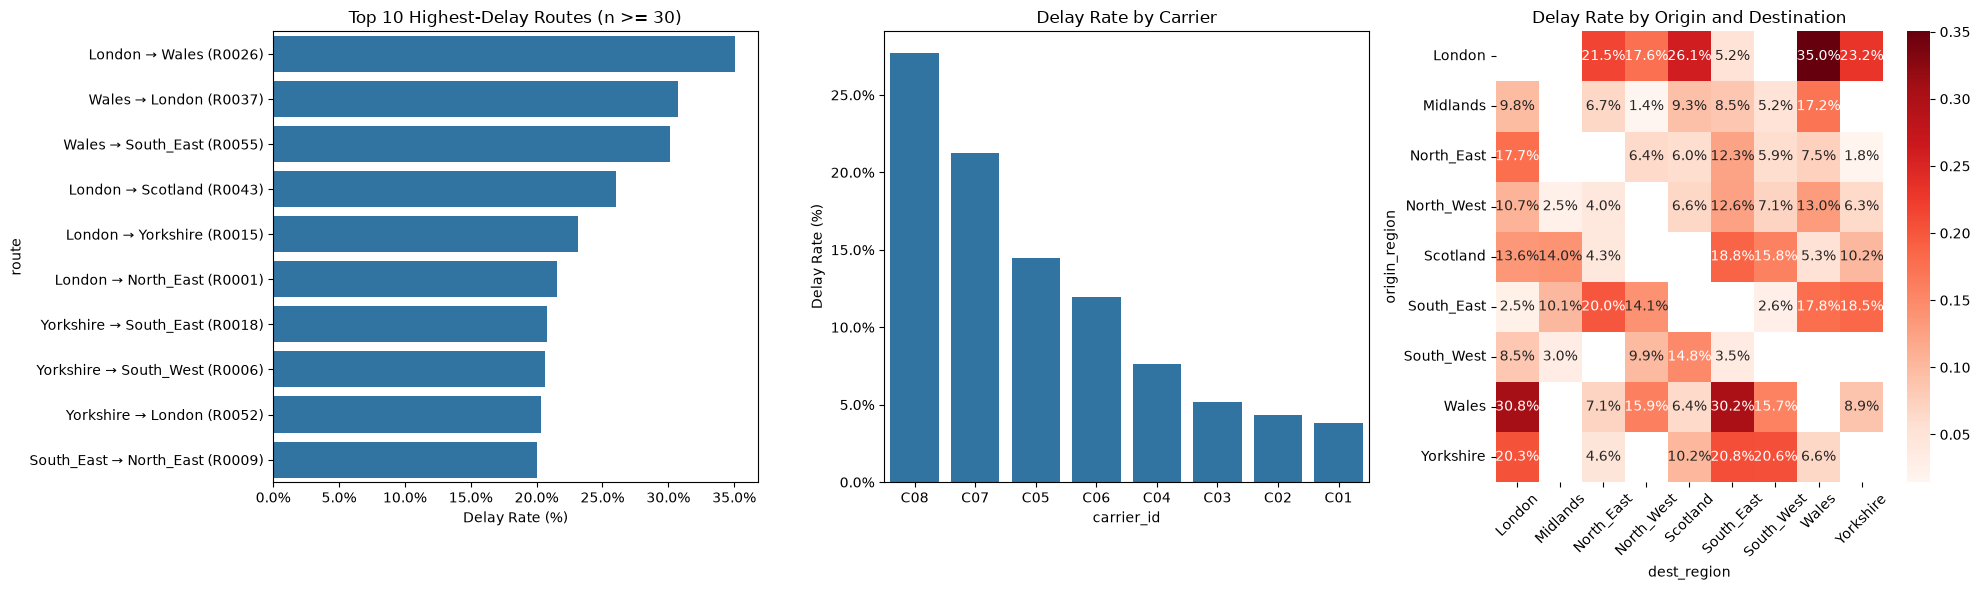

,route,Shipments,Delay rate (%)
25,London → Wales (R0026),177,35.0
36,Wales → London (R0037),156,30.8
54,Wales → South_East (R0055),179,30.2
42,London → Scotland (R0043),165,26.1
14,London → Yorkshire (R0015),177,23.2
0,London → North_East (R0001),195,21.5
17,Yorkshire → South_East (R0018),149,20.8
5,Yorkshire → South_West (R0006),165,20.6
51,Yorkshire → London (R0052),172,20.3
8,South_East → North_East (R0009),160,20.0


In [6]:
# *(2 marks)* Show: top 10 highest-delay routes, delay rate by carrier,
# and a heatmap of delay rate by origin x destination region.

# Your code here
from swiftroute.plots import plot_risky_routes_carriers

route_risk = plot_risky_routes_carriers(data)

top10 = route_risk[route_risk["n"] >= 30].nlargest(10, "delay_rate").copy()
top10["delay_rate"] = (top10["delay_rate"] * 100).round(1)
display(top10[["route", "n", "delay_rate"]].rename(columns={"n": "Shipments", "delay_rate": "Delay rate (%)"}))

**Commentary** - Which two route/carrier combinations are riskiest? Business implication?

*Your answer here.*

From the plots, two riskiest combinations among the top four highest-delay routes are R0026 (London -> Wales) with C07 (60.9%) and R0043 (London -> Scotland) with C08 (60.0%).

I noticed that the same route can have very different delay rates depending on the carrier. For example, C01 has only 3.2% delays on R0026, compared to 60.9% for C07. This suggests that carrier choice matters.

I think Operations should investigate these combinations and consider switching to more reliable carriers. However, each combination has only 23-25 shipments, so more data is needed before making decisions.

---
# SECTION 4 - Cleaning & Joining the Data *(12 marks)*

In [7]:
# *(2 marks)* 4.1 - Remove duplicate shipments. Keep first occurrence.

# Your code here
from swiftroute.dataset import clean_dataset, join_routes_carriers, join_weather

cleaned_data = clean_dataset(data)

print("Duplicates removed:", len(data["shipments"]) - len(cleaned_data["shipments"]))

Duplicates removed: 0


In [8]:
# *(4 marks)* 4.2 - Join routes and carriers to shipments.
# Bring in: distance_km, n_depot_hops, historical_delay_rate, avg_transit_days
# from routes; reliability_score, capacity_utilisation from carriers.

# Your code here
df = join_routes_carriers(cleaned_data)

print("Joined shape:", df.shape)
display(df.head())


Joined shape: (10025, 18)


,shipment_id,pickup_date,origin_region,dest_region,service_tier,carrier_id,route_id,weight_kg,volume_cm3,declared_value,is_business,is_delayed,distance_km,n_depot_hops,historical_delay_rate,avg_transit_days,reliability_score,capacity_utilisation
0,SH0000001,2025-09-26,London,North_West,economy,C03,R0038,11.54,9427,5.44,0,0,438,3,0.1999,2.69,0.8605,0.6675
1,SH0000002,2024-12-09,North_West,North_East,standard,C01,R0044,9.26,9864,7.48,1,0,159,1,0.0944,1.68,0.9508,0.5926
2,SH0000003,2025-11-15,South_East,South_West,express,C05,R0013,0.43,96,37.44,0,0,180,1,0.0998,1.99,0.7640,0.8150
3,SH0000004,2025-06-12,South_East,North_East,express,C08,R0009,8.84,6541,141.25,0,1,433,3,0.1825,2.61,0.5871,0.9049
4,SH0000005,2026-03-21,Yorkshire,Scotland,standard,C04,R0010,11.10,4959,148.71,0,0,153,1,0.1086,1.55,0.8332,0.7361


In [9]:
# *(6 marks)* 4.3 - Join weather events.
# For each shipment, determine the maximum weather severity affecting its
# origin region and destination region on its pickup_date.
# Hint: a shipment at row i is weather-affected at origin if there exists any
# weather event where region == origin_region AND start_date <= pickup_date <= end_date.

# Your code here
# master = ...
master = join_weather(df, cleaned_data["weather"])

print("Joined shape:", master.shape)
print("Duplicate shipment IDs:", master["shipment_id"].duplicated().sum())
display(master["weather_severity"].value_counts().sort_index())

Joined shape: (10025, 21)
Duplicate shipment IDs: 0


weather_severity
0    7106
1    1181
2     989
3     749
Name: count, dtype: int64

---
# SECTION 5 - Creating New Features *(15 marks)*

In [10]:
# *(9 marks)* Create at least 5 new features. Comment each with its rationale.
#
# Suggested directions:
# - weather_affected: binary flag - any weather at origin OR destination
# - weather_both_ends: both origin AND destination affected
# - is_winter: pickup in Nov-Feb (higher disruption risk)
# - volume_to_weight: proxy for irregular/awkward parcels
# - carrier_route_risk: carrier reliability * route historical delay rate
# - day_of_week: Monday/Friday shipments may face different delays
# - is_cross_region: same vs different region (local vs long-haul)

# Your code here
from swiftroute.features import add_features

master = add_features(master)

new_features = set(master.columns) - set(df.columns)
print("Shape before feature engineering:", df.shape)
print("Shape after feature engineering:", master.shape)
print("New features added:", new_features)
display(master[list(new_features)].head())

print("Weather at both ends:", master["weather_both_ends"].sum())
print("Weather at either end:", master["weather_affected"].sum())
print("Shape:", master.shape)

Shape before feature engineering: (10025, 18)
Shape after feature engineering: (10025, 26)
New features added: {'is_winter', 'day_of_week', 'volume_to_weight', 'weather_severity', 'carrier_route_risk', 'is_cross_region', 'weather_affected', 'weather_both_ends'}


,is_winter,day_of_week,volume_to_weight,weather_severity,carrier_route_risk,is_cross_region,weather_affected,weather_both_ends
0,0,4,816.897747,1,0.027886,1,True,0
1,1,0,1065.226782,0,0.004644,1,False,0
2,1,5,223.255814,0,0.023553,1,False,0
3,0,3,739.932127,3,0.075354,1,True,0
4,0,5,446.756757,0,0.018114,1,False,0


Weather at both ends: 268
Weather at either end: 2919
Shape: (10025, 26)


***(6 marks)* Explain your new features.**

For each feature, explain what it measures and why it should predict delays.

*Your answer here.*

1. `weather_affected`: This checks whether a shipment has a weather event at its origin or destination on the pickup date. From Section 3.3, I found that weather-affected shipments have about three times the delay rate, so this could help identify risky shipments.

2. `weather_both_ends`: This checks whether both the origin and destination are affected by weather. I think disruptions at both ends may increase the chance of delays because the shipment could face problems at multiple locations.

3. `weather_severity`: This measures the highest weather severity affecting a shipment, from 0 (no event) to 3 (severe). More severe weather may cause longer disruptions, so this gives the model more information than a simple weather flag.

4. `is_winter`: This indicates whether a shipment was picked up between November and February. From Section 3.2, I noticed higher delay rates in some winter months, so this may help capture seasonal risk.

5. `volume_to_weight`: This measures parcel volume relative to its weight. A higher value may indicate a bulky but lightweight parcel that requires more space or handling, which could affect delivery time.

6. `carrier_route_risk`: This combines carrier unreliability (`1 - reliability_score`) with the route's historical delay rate. Since both factors are related to delays, I think combining them may help identify higher-risk shipments.

7. `day_of_week`: This represents the pickup day, from Monday (0) to Sunday (6). Delivery schedules and staffing may differ throughout the week, which could affect delays.

8. `is_cross_region`: This checks whether the origin and destination are in different regions. Cross-region shipments may involve more transportation and handling. However, all shipments in this dataset are cross-region, so this feature may not help distinguish delay risks.


---
# SECTION 6 - Training Models *(15 marks)*

In [11]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

EXCLUDE = ['shipment_id','pickup_date','origin_region','dest_region',
           'carrier_id','route_id','is_delayed']
# Add any categorical columns you haven't encoded yet

feature_cols = [c for c in master.columns if c not in EXCLUDE]
X = master[feature_cols]
y = master['is_delayed']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print(f'Train: {len(X_train):,}  Val: {len(X_val):,}  Delay rate val: {y_val.mean():.2%}')

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = {}

Train: 8,020  Val: 2,005  Delay rate val: 11.92%


In [12]:
# *(3 marks)* Model 1 - Logistic Regression
from sklearn.linear_model import LogisticRegression

# Your code here
from swiftroute.modeling.train import split_data, logistic_model, forest_model, evaluate_model, compare_models

X_train, X_val, y_train, y_val = split_data(master)
print(f'Train: {len(X_train):,}, Validation: {len(X_val):,}, Validation delay rate: {y_val.mean():.2%}')

results = {}

results["Logistic Regression"] = evaluate_model(logistic_model(X_train), X_train, X_val, y_train, y_val)


Train: 8,020, Validation: 2,005, Validation delay rate: 11.92%


***(2 marks)* Model 1 - explain your choices.**

- Why LR for delay prediction?
- How did you handle class imbalance?
- What regularisation and why?

*Your answer here.*

I chose Logistic Regression (LR) for delay prediction because it is simple, easy to interpret, and provides probabilities that Operations can use to identify high-risk shipments.

I handled class imbalance by using class_weight="balanced" because only about 12% of shipments are delayed. This gives more weight to delayed shipments so the model does not favor the majority class.

I used L2 regularisation (C=1.0) to reduce overfitting by limiting large coefficients, especially since some features are correlated.

In [13]:
# *(3 marks)* Model 2 - Random Forest or LightGBM

# Your code here
results["Random Forest"] = evaluate_model(forest_model(X_train), X_train, X_val, y_train, y_val)

***(2 marks)* Model 2 - explain your choices.**

*Your answer here.*

I chose Random Forest because delivery delays may depend on multiple factors working together, such as an unreliable carrier on a long route. It can capture non-linear relationships and interactions that Logistic Regression may miss.

I used 150 trees to make predictions more stable, with max_depth=10 and min_samples_leaf=5 to reduce overfitting. I also used class_weight="balanced_subsample" to handle class imbalance by giving more importance to delayed shipments.

In [14]:
# *(2 marks)* Compare models. Print CV AUC, Val AUC, overfit gap.

# Your code here

# best_prob  = None
# best_model = None

display(compare_models(results))
best_name = max(results, key=lambda name: results[name]["val_auc"])
best_model = results[best_name]["model"]
best_prob = results[best_name]["val_prob"]

print(f"Best model: {best_name}")

,CV AUC,Validation AUC,Training AUC,Overfit gap
Logistic Regression,0.866,0.863,0.870,0.007
Random Forest,0.849,0.851,0.962,0.111


Best model: Logistic Regression


***(3 marks)* Which model did you choose and why?**

*Your answer here.*

I chose Logistic Regression because it has a higher validation AUC (0.863 vs 0.851) than Random Forest, meaning it is better at ranking delayed shipments above on-time ones. Logistic Regression also has a smaller overfit gap (0.007 vs 0.111), suggesting it generalises better to unseen shipments. Although Random Forest performs better on training data, its validation performance drops significantly, indicating overfitting. Therefore, I think Logistic Regression is a better choice because it performs more consistently and is easier to interpret.

---
# SECTION 7 - Evaluating Your Model *(8 marks)*

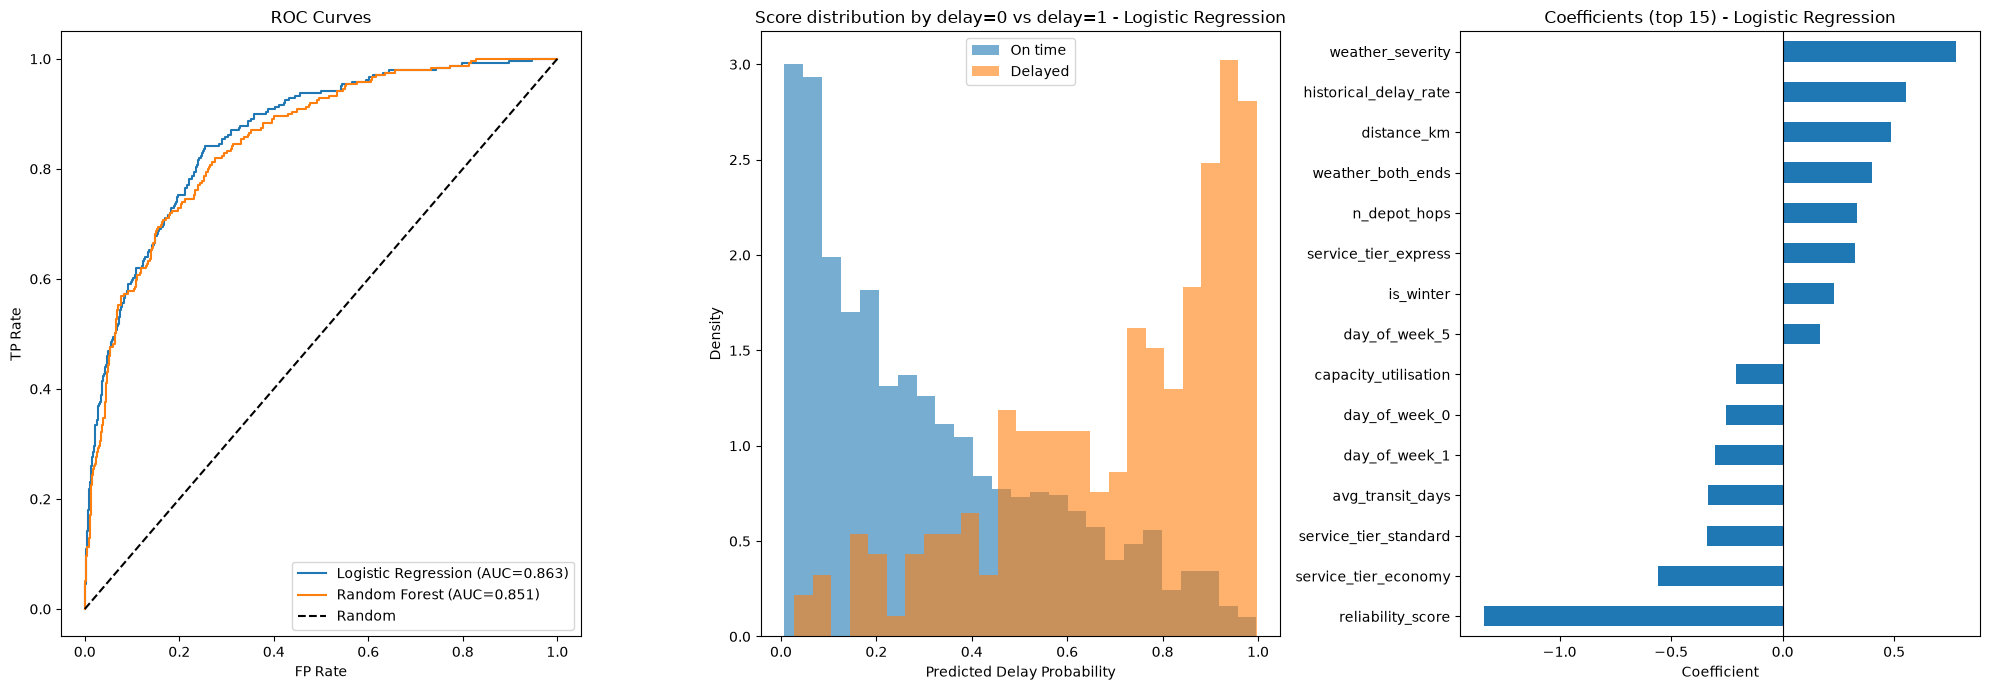

In [15]:
# *(8 marks)* Produce:
# 1. ROC curves for all models
# 2. Score distribution by delay=0 vs delay=1
# 3. Feature importance / coefficients (top 15)

# Your code here

from swiftroute.plots import plot_model_diagnostics

plot_model_diagnostics(results, y_val, best_name)

**Interpret your diagnostics.**

*Your answer here.*

From the diagnostic plots, I noticed three main findings:

- ROC curves: Both models perform well above the random baseline. Logistic Regression has a slightly higher AUC (0.863) than Random Forest (0.851), supporting my choice of Logistic Regression.

- Score distribution: On-time shipments tend to receive lower risk scores, while delayed shipments receive higher scores. However, some overlap remains, meaning the model can still make mistakes. Since I used class_weight="balanced", the scores may not be well calibrated, so they are more useful for ranking shipments than estimating exact delay probabilities.

- Feature coefficients: Weather severity, historical delay rate, and distance have strong positive coefficients, while carrier reliability has the strongest negative coefficient. This suggests that severe weather and longer routes increase predicted delay risk, while reliable carriers reduce it. However, correlated features may affect how individual coefficients are interpreted.

Overall, I think the model can help identify high-risk shipments. I will check the delay capture rate in the top 15% to evaluate its business value.

---
# SECTION 8 - Business Impact *(12 marks)*

In [16]:
# *(7 marks)* Compute the delay capture rate at 15% intervention.
#
# Delay capture rate = (# actual delays in top-15% flagged) / (# total actual delays)
#
# Compare:
#   (a) Random 15% policy
#   (b) Model top-15% policy
#
# Also compute: SLA penalty avoided.
# Assume each avoided delay saves £45 in SLA penalties + handling costs.

# Your code here

***(5 marks)* What is the business impact?**

Explain in plain language the value of flagging high-risk shipments vs random selection.
What would you recommend to SwiftRoute's Operations team?

*Your answer here.*

---
## 8.2 - Save Your Model for Deployment

In [17]:
import joblib

joblib.dump(best_model, 'model.pkl')
print('Model saved to model.pkl')

Model saved to model.pkl


---
# SECTION 9 - Monitoring for Drift in Production *(5 marks)*

**9.1** *(2 marks)* Propose how you would detect **input drift** on the live shipment stream. Which features are most likely to drift and what tests would you use?

*Your answer here.*

---

**9.2** *(3 marks)* Propose how you would detect **target drift** - i.e. the actual delay rate changing in ways the model no longer predicts correctly. What would trigger retraining?

*Your answer here.*

---
# EXTENSION *(10 marks)*

Attempt **both** tasks (5 marks each).

**E1** *(5 marks)* **Route-level analysis**: cluster routes by risk profile. Can you identify systematic weaknesses in SwiftRoute's network?

**E2** *(5 marks)* **SHAP**: for the top 10 highest-risk shipments in the validation set, use SHAP to explain exactly which factors are driving each prediction.